In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from river import anomaly
from river import metrics
from river import preprocessing
from yellowbrick.target import FeatureCorrelation

In [2]:
# Read from csv file
model_df = pd.read_csv("data/network_anomaly_detection.csv", low_memory=False)
model_df.head()

,window_id,window_start,packet_count,bytes_per_second,avg_packet_size,packet_size_std,unique_protocols,unique_src_ips,unique_dst_ips,unique_src_ports,...,retransmission_count,retransmission_rate,internal_external_ratio,ttl_mean,ttl_std,http_get_count,http_post_count,http_other_count,is_baseline,file_source
0,29032552,1741953120,9740,119999.300000,739.215400,610.574299,0,54,58,211,...,20,0.002053,0.037037,89.496798,65.729058,0,0,0,True,baseline_day2.pcap
1,29032524,1741951440,99,197.183333,119.505051,105.328478,0,9,9,14,...,8,0.080808,0.200000,58.015385,14.030179,0,0,0,True,baseline_day2.pcap
2,29034261,1742055660,998,8443.100000,507.601202,581.354821,0,24,25,64,...,17,0.017034,0.113636,63.255249,21.333242,0,0,0,True,baseline_day3.pcap
3,29028278,1741696680,11388,163767.716667,862.843607,632.807597,0,44,47,168,...,11,0.000966,0.000000,96.454697,77.437518,0,0,0,True,baseline_day1.pcap
4,29038195,1742291700,508,2259.566667,266.877953,360.970751,0,4,5,39,...,5,0.009843,0.000000,202.347826,81.136283,0,0,0,True,baseline_day4.pcap


In [3]:
# Take a look at the counts of the anomalous traffic data (where is_baseline is False)
model_df["is_baseline"].value_counts()

is_baseline
True     245
False     61
Name: count, dtype: int64

In [4]:
# Take a look at the proportion of the anomalous traffic data
model_df["is_baseline"].value_counts(normalize=True)

is_baseline
True     0.800654
False    0.199346
Name: proportion, dtype: float64

In [5]:
# Create a new column called anomaly that is set to 1 if is_baseline is False and 0 if is_baseline is True
model_df["anomaly"] = model_df["is_baseline"].apply(lambda x: 0 if x else 1)
model_df

,window_id,window_start,packet_count,bytes_per_second,avg_packet_size,packet_size_std,unique_protocols,unique_src_ips,unique_dst_ips,unique_src_ports,...,retransmission_rate,internal_external_ratio,ttl_mean,ttl_std,http_get_count,http_post_count,http_other_count,is_baseline,file_source,anomaly
0,29032552,1741953120,9740,1.199993e+05,739.215400,610.574299,0,54,58,211,...,0.002053,0.037037,89.496798,65.729058,0,0,0,True,baseline_day2.pcap,0
1,29032524,1741951440,99,1.971833e+02,119.505051,105.328478,0,9,9,14,...,0.080808,0.200000,58.015385,14.030179,0,0,0,True,baseline_day2.pcap,0
2,29034261,1742055660,998,8.443100e+03,507.601202,581.354821,0,24,25,64,...,0.017034,0.113636,63.255249,21.333242,0,0,0,True,baseline_day3.pcap,0
3,29028278,1741696680,11388,1.637677e+05,862.843607,632.807597,0,44,47,168,...,0.000966,0.000000,96.454697,77.437518,0,0,0,True,baseline_day1.pcap,0
4,29038195,1742291700,508,2.259567e+03,266.877953,360.970751,0,4,5,39,...,0.009843,0.000000,202.347826,81.136283,0,0,0,True,baseline_day4.pcap,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
301,29028263,1741695780,5685,7.004762e+04,739.288830,628.652687,0,39,38,129,...,0.001055,0.000000,57.152059,11.623331,0,0,0,True,baseline_day1.pcap,0
302,29034221,1742053260,2797,2.506972e+04,537.784412,580.488768,0,30,30,71,...,0.000000,0.176471,65.370316,29.567754,0,0,0,True,baseline_day3.pcap,0
303,29034256,1742055360,2345,2.681183e+04,686.017058,600.555825,0,12,14,37,...,0.101919,0.181818,63.777632,17.846168,0,0,0,True,baseline_day3.pcap,0
304,29045420,1742725200,94075,1.707742e+06,1089.179251,390.847019,0,18,21,49,...,0.000181,0.114286,115.586379,18.438964,0,0,2,False,anomalies.pcap,1


In [6]:
# Define features and target varuable
X = model_df.drop(columns=["is_baseline", "anomaly", "unique_protocols", "http_post_count", "http_other_count", "file_source", "window_start", "window_id"])
y = model_df["anomaly"]

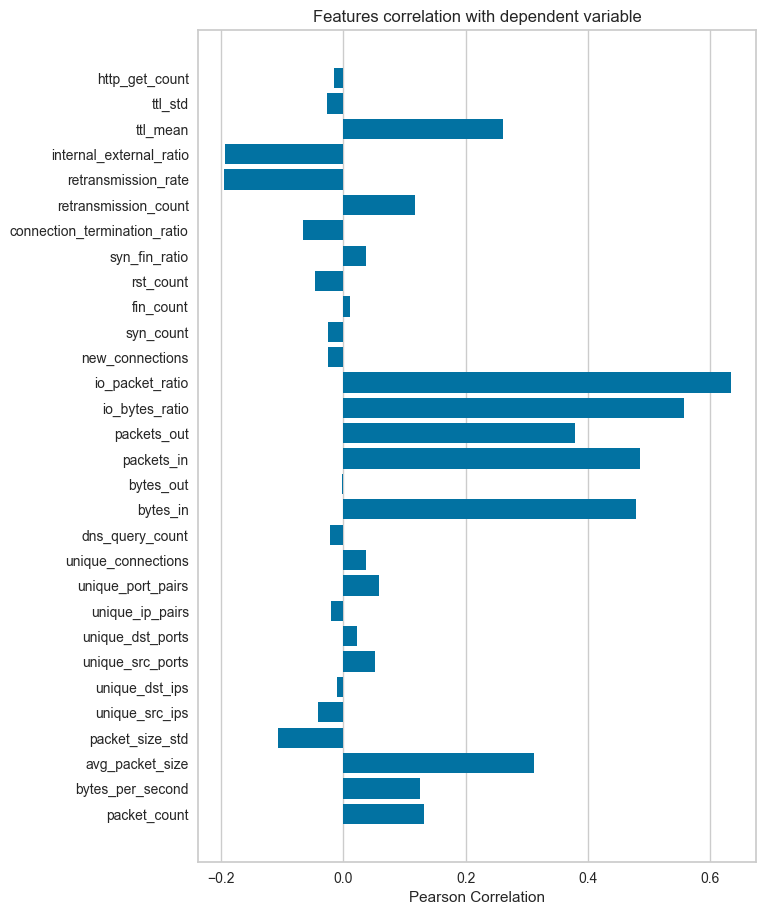

<Axes: title={'center': 'Features correlation with dependent variable'}, xlabel='Pearson Correlation'>

In [7]:
# Visualize the correlation between features and the target variable
feat_corr = FeatureCorrelation(labels=X.columns, size=(720, 1080))
feat_corr.fit(X, y)
feat_corr.show()

In [8]:
# First Experiment with Half Space Trees
# Scale features
# Set quantile threshold = 0.3 (values above this threshold are considered anomalies)
# The precision and recall metrics are not that good
hst = anomaly.QuantileFilter(
    anomaly.HalfSpaceTrees(n_trees=5, 
                           height=3, 
                           window_size=3,
                           seed=42),
    q=0.3
)
recall = metrics.Recall(pos_val=1)
precision = metrics.Precision(pos_val=1)
cr = metrics.ClassificationReport()
cm = metrics.ConfusionMatrix(classes=[0, 1])
scaler = preprocessing.MinMaxScaler()
pred_dict_list = []
for i in range(0, len(model_df)):
    row = model_df.iloc[i]
    # Use the features with the highest correlation to the target variable
    x = row[["io_packet_ratio", "io_bytes_ratio", "packets_out", "packets_in", "bytes_out"]].to_dict()
    scaler.learn_one(x)
    scaler.transform_one(x)
    y = row["anomaly"]
    score = hst.score_one(x)
    y_pred = 1 if hst.classify(score) else 0
    print(f"Score: {score}, Pred: {y_pred}, Actual: {y}")
    hst.learn_one(x)
    pred_dict = {"y_pred": y_pred, "actual": y, "score": score, "precision": precision, "recall": recall}
    pred_dict_list.append(pred_dict)
    # Update metrics
    cr.update(y, y_pred)
    cm.update(y, y_pred)
    precision.update(y, y_pred)
    recall.update(y, y_pred)
    print(f"{precision}, {recall}")
pred_df = pd.DataFrame(pred_dict_list)

Score: 0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.9333333333333333, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.9333333333333333, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.7555555555555555, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.6222222222222222, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.7555555555555555, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.30222222222222217, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.30222222222222217, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.30222222222222217, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.29333333333333333, Pred: 1, Actual: 0
Precision: 0.00%,

In [9]:
cm

    0     1    
0   111   134  
1    59     2  

In [10]:
cr

           Precision   Recall   F1       Support  
                                                  
       0      65.29%   45.31%   53.49%       245  
       1       1.47%    3.28%    2.03%        61  
                                                  
   Macro      33.38%   24.29%   27.76%            
   Micro      36.93%   36.93%   36.93%            
Weighted      52.57%   36.93%   43.23%            

                 36.93% accuracy                  

In [11]:
# Second experiment with Half Space Trees
# Try changing some of the parameters
# The precision and recall metrics are better but are still not good
hst = anomaly.QuantileFilter(
    anomaly.HalfSpaceTrees(n_trees=10, 
                           height=5, 
                           window_size=5,
                           seed=42),
    q=0.3
)
recall = metrics.Recall(pos_val=1)
precision = metrics.Precision(pos_val=1)
cr = metrics.ClassificationReport()
cm = metrics.ConfusionMatrix(classes=[0, 1])
scaler = preprocessing.MinMaxScaler()
pred_dict_list = []
for i in range(0, len(model_df)):
    row = model_df.iloc[i]
    x = row[["io_packet_ratio", "io_bytes_ratio", "packets_out", "packets_in", "bytes_out"]].to_dict()
    scaler.learn_one(x)
    scaler.transform_one(x)
    y = row["anomaly"]
    score = hst.score_one(x)
    y_pred = 1 if hst.classify(score) else 0
    print(f"Score: {score}, Pred: {y_pred}, Actual: {y}")
    hst.learn_one(x)
    pred_dict = {"y_pred": y_pred, "actual": y, "score": score, "precision": precision, "recall": recall}
    pred_dict_list.append(pred_dict)
    # Update metrics
    cr.update(y, y_pred)
    cm.update(y, y_pred)
    precision.update(y, y_pred)
    recall.update(y, y_pred)
    print(f"{precision}, {recall}")
pred_df = pd.DataFrame(pred_dict_list)

Score: 0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.4634920634920635, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.8806349206349207, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.4634920634920635, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.933968253968254, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.6247619047619047, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.42412698412698413, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.42412698412698413, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.47492063492063497, Pred: 1, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.573968253968254, Pred: 1, Actual: 0
Precision: 0.00%, Recall

In [12]:
cm

    0    1    
0   66   179  
1   49    12  

In [13]:
cr

           Precision   Recall   F1       Support  
                                                  
       0      57.39%   26.94%   36.67%       245  
       1       6.28%   19.67%    9.52%        61  
                                                  
   Macro      31.84%   23.31%   23.10%            
   Micro      25.49%   25.49%   25.49%            
Weighted      47.20%   25.49%   31.26%            

                 25.49% accuracy                  

In [14]:
# Third experiment with Half Space Trees
# Try changing the quantile threshold
# The precision and recall metrics are worse than the second experiment
hst = anomaly.QuantileFilter(
    anomaly.HalfSpaceTrees(n_trees=10, 
                           height=5, 
                           window_size=5,
                           seed=42),
    q=0.4
)
recall = metrics.Recall(pos_val=1)
precision = metrics.Precision(pos_val=1)
cr = metrics.ClassificationReport()
cm = metrics.ConfusionMatrix(classes=[0, 1])
scaler = preprocessing.MinMaxScaler()
pred_dict_list = []
for i in range(0, len(model_df)):
    row = model_df.iloc[i]
    x = row[["io_packet_ratio", "io_bytes_ratio", "packets_out", "packets_in", "bytes_out"]].to_dict()
    scaler.learn_one(x)
    scaler.transform_one(x)
    y = row["anomaly"]
    score = hst.score_one(x)
    y_pred = 1 if hst.classify(score) else 0
    print(f"Score: {score}, Pred: {y_pred}, Actual: {y}")
    hst.learn_one(x)
    pred_dict = {"y_pred": y_pred, "actual": y, "score": score, "precision": precision, "recall": recall}
    pred_dict_list.append(pred_dict)
    # Update metrics
    cr.update(y, y_pred)
    cm.update(y, y_pred)
    precision.update(y, y_pred)
    recall.update(y, y_pred)
    print(f"{precision}, {recall}")
pred_df = pd.DataFrame(pred_dict_list)

Score: 0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.4634920634920635, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.8806349206349207, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.4634920634920635, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.933968253968254, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.6247619047619047, Pred: 1, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.4634920634920635, Pred: 1, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.4634920634920635, Pred: 1, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.4431746031746032, Pred: 1, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.7555555555555555, Pred: 1, Actual: 0
Precision: 0.00%, Recall: 

In [15]:
cm

    0    1    
0   79   166  
1   53     8  

In [16]:
cr

           Precision   Recall   F1       Support  
                                                  
       0      59.85%   32.24%   41.91%       245  
       1       4.60%   13.11%    6.81%        61  
                                                  
   Macro      32.22%   22.68%   24.36%            
   Micro      28.43%   28.43%   28.43%            
Weighted      48.83%   28.43%   34.91%            

                 28.43% accuracy                  

In [17]:
# First experiment with One Class SVM
# Recall is high, but precision is low, and much better than Half Space Trees
# Good at detecting anomalies, but many false positives
model_one_class_svm = anomaly.QuantileFilter(
    anomaly.OneClassSVM(nu=0.2,),
    q=0.3,
)
recall = metrics.Recall(pos_val=1)
precision = metrics.Precision(pos_val=1)
cr = metrics.ClassificationReport()
cm = metrics.ConfusionMatrix(classes=[0, 1])
scaler = preprocessing.StandardScaler()
pred_dict_list = []
for i in range(0, len(model_df)):
    row = model_df.iloc[i]
    x = row[["io_packet_ratio", "io_bytes_ratio", "packets_out", "packets_in", "bytes_out"]].to_dict()
    scaler.learn_one(x)
    scaler.transform_one(x)
    y = row["anomaly"]
    score = model_one_class_svm.score_one(x)
    y_pred = 1 if model_one_class_svm.classify(score) else 0
    print(f"Score: {score}, Pred: {y_pred}, Actual: {y}")
    model_one_class_svm.learn_one(x)
    pred_dict = {"y_pred": y_pred, "actual": y, "score": score, "precision": precision, "recall": recall}
    pred_dict_list.append(pred_dict)
    # Update metrics
    cr.update(y, y_pred)
    cm.update(y, y_pred)
    precision.update(y, y_pred)
    recall.update(y, y_pred)
    print(f"Precision: {precision}, Recall: {recall}")
pred_df = pd.DataFrame(pred_dict_list)

Score: 0.0, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 37276207.67181392, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 4247421871.289543, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 0.0, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 0.0, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 1623022965.1166258, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 15392662879.693079, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 728549437.8048288, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 28776333906.47046, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 1088906488.0290163, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 1345022722.3790224, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Reca

In [18]:
cm

    0    1    
0   90   155  
1    6    55  

In [19]:
cr

           Precision   Recall   F1       Support  
                                                  
       0      93.75%   36.73%   52.79%       245  
       1      26.19%   90.16%   40.59%        61  
                                                  
   Macro      59.97%   63.45%   46.69%            
   Micro      47.39%   47.39%   47.39%            
Weighted      80.28%   47.39%   50.35%            

                 47.39% accuracy                  

In [20]:
# Second experiment with One Class SVM
# Change the quantile threshold to 0.4
# The precision barely changed, and the recall is worse than the first experiment
model_one_class_svm = anomaly.QuantileFilter(
    anomaly.OneClassSVM(nu=0.2,),
    q=0.4,
)
recall = metrics.Recall(pos_val=1)
precision = metrics.Precision(pos_val=1)
cr = metrics.ClassificationReport()
cm = metrics.ConfusionMatrix(classes=[0, 1])
scaler = preprocessing.StandardScaler()
pred_dict_list = []
for i in range(0, len(model_df)):
    row = model_df.iloc[i]
    x = row[["io_packet_ratio", "io_bytes_ratio", "packets_out", "packets_in", "bytes_out"]].to_dict()
    scaler.learn_one(x)
    scaler.transform_one(x)
    y = row["anomaly"]
    score = model_one_class_svm.score_one(x)
    y_pred = 1 if model_one_class_svm.classify(score) else 0
    print(f"Score: {score}, Pred: {y_pred}, Actual: {y}")
    model_one_class_svm.learn_one(x)
    pred_dict = {"y_pred": y_pred, "actual": y, "score": score, "precision": precision, "recall": recall}
    pred_dict_list.append(pred_dict)
    # Update metrics
    cr.update(y, y_pred)
    cm.update(y, y_pred)
    precision.update(y, y_pred)
    recall.update(y, y_pred)
    print(f"Precision: {precision}, Recall: {recall}")
pred_df = pd.DataFrame(pred_dict_list)

Score: 0.0, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 37276207.67181392, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 4247421871.289543, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 0.0, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 0.0, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 1623022965.1166258, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 15392662879.693079, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 728549437.8048288, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 28776333906.47046, Pred: 0, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 1088906488.0290163, Pred: 1, Actual: 0
Precision: Precision: 0.00%, Recall: Recall: 0.00%
Score: 1346369091.470493, Pred: 1, Actual: 0
Precision: Precision: 0.00%, Recal

In [21]:
cm

    0     1    
0   112   133  
1    14    47  

In [22]:
cr

           Precision   Recall   F1       Support  
                                                  
       0      88.89%   45.71%   60.38%       245  
       1      26.11%   77.05%   39.00%        61  
                                                  
   Macro      57.50%   61.38%   49.69%            
   Micro      51.96%   51.96%   51.96%            
Weighted      76.37%   51.96%   56.12%            

                 51.96% accuracy                  

In [23]:
# Third experiment with One Class SVM
# Try using the two features that had the highest correlation and 
# Change the quantile threshold back to 0.3
# Both the precision and recall have improved
# The model detected most anomalies, but there are still a lot of false positives
model_one_class_svm = anomaly.QuantileFilter(
        anomaly.OneClassSVM(nu=0.2,),
        q=0.3,
    )
recall = metrics.Recall(pos_val=1)
precision = metrics.Precision(pos_val=1)
cr = metrics.ClassificationReport()
cm = metrics.ConfusionMatrix(classes=[0, 1])
scaler = preprocessing.StandardScaler()
pred_dict_list = []
for i in range(0, len(model_df)):
    row = model_df.iloc[i]
    x = row[["io_packet_ratio", "io_bytes_ratio"]].to_dict()
    scaler.learn_one(x)
    scaler.transform_one(x)
    y = row["anomaly"]
    score = model_one_class_svm.score_one(x)
    y_pred = 1 if model_one_class_svm.classify(score) else 0
    print(f"Score: {score}, Pred: {y_pred}, Actual: {y}")
    model_one_class_svm.learn_one(x)
    pred_dict = {"y_pred": y_pred, "actual": y, "score": score, "precision": precision.get(), "recall": recall.get()}
    pred_dict_list.append(pred_dict)
    # Update metrics
    cr.update(y, y_pred)
    cm.update(y, y_pred)
    precision.update(y, y_pred)
    recall.update(y, y_pred)
    print(f"{precision}, {recall}")
pred_df = pd.DataFrame(pred_dict_list)

Score: 0.0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.04181392082552171, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.04433289371972693, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.31284492854870405, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.017282340719087186, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.12981975238062904, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.013439473490125975, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.04543442895983185, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.10823240669750334, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.0573743250005625, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.04441250042395639, Pred: 1, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.02701092857

In [24]:
cm

    0    1    
0   99   146  
1    0    61  

In [25]:
cr

           Precision   Recall    F1       Support  
                                                   
       0     100.00%    40.41%   57.56%       245  
       1      29.47%   100.00%   45.52%        61  
                                                   
   Macro      64.73%    70.20%   51.54%            
   Micro      52.29%    52.29%   52.29%            
Weighted      85.94%    52.29%   55.16%            

                  52.29% accuracy                  

In [26]:
# Fourth experiment with One Class SVM
# Change the quantile threshold to 0.4
# Both the precision and recall have improved
# The precision is better with only a slight decrease in recall
model_one_class_svm = anomaly.QuantileFilter(
        anomaly.OneClassSVM(nu=0.2,),
        q=0.4,
    )
recall = metrics.Recall(pos_val=1)
precision = metrics.Precision(pos_val=1)
cr = metrics.ClassificationReport()
cm = metrics.ConfusionMatrix(classes=[0, 1])
scaler = preprocessing.StandardScaler()
pred_dict_list = []
for i in range(0, len(model_df)):
    row = model_df.iloc[i]
    x = row[["io_packet_ratio", "io_bytes_ratio"]].to_dict()
    scaler.learn_one(x)
    scaler.transform_one(x)
    y = row["anomaly"]
    score = model_one_class_svm.score_one(x)
    y_pred = 1 if model_one_class_svm.classify(score) else 0
    print(f"Score: {score}, Pred: {y_pred}, Actual: {y}")
    model_one_class_svm.learn_one(x)
    pred_dict = {"y_pred": y_pred, "actual": y, "score": score, "precision": precision.get(), "recall": recall.get()}
    pred_dict_list.append(pred_dict)
    # Update metrics
    cr.update(y, y_pred)
    cm.update(y, y_pred)
    precision.update(y, y_pred)
    recall.update(y, y_pred)
    print(f"{precision}, {recall}")
pred_df = pd.DataFrame(pred_dict_list)

Score: 0.0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.04181392082552171, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.04433289371972693, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.31284492854870405, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.017282340719087186, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.12981975238062904, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.013439473490125975, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.04543442895983185, Pred: 1, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.10834074744494826, Pred: 1, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.05748924600332317, Pred: 1, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.044546004845023024, Pred: 1, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.027092123

In [27]:
cm

    0     1    
0   127   118  
1     2    59  

In [28]:
cr

           Precision   Recall   F1       Support  
                                                  
       0      98.45%   51.84%   67.91%       245  
       1      33.33%   96.72%   49.58%        61  
                                                  
   Macro      65.89%   74.28%   58.75%            
   Micro      60.78%   60.78%   60.78%            
Weighted      85.47%   60.78%   64.26%            

                 60.78% accuracy                  

In [29]:
# Fifth experiment with One Class SVM
# Change the quantile threshold to 0.6
# Both the precision and recall have improved
# The precision is better than the previous experiment and the recall has decreased marginally
model_one_class_svm = anomaly.QuantileFilter(
        anomaly.OneClassSVM(nu=0.2,),
        q=0.6,
    )
recall = metrics.Recall(pos_val=1)
precision = metrics.Precision(pos_val=1)
cr = metrics.ClassificationReport()
cm = metrics.ConfusionMatrix(classes=[0, 1])
scaler = preprocessing.StandardScaler()
pred_dict_list = []
for i in range(0, len(model_df)):
    row = model_df.iloc[i]
    x = row[["io_packet_ratio", "io_bytes_ratio"]].to_dict()
    scaler.learn_one(x)
    scaler.transform_one(x)
    y = row["anomaly"]
    score = model_one_class_svm.score_one(x)
    y_pred = 1 if model_one_class_svm.classify(score) else 0
    print(f"Score: {score}, Pred: {y_pred}, Actual: {y}")
    model_one_class_svm.learn_one(x)
    pred_dict = {"y_pred": y_pred, "actual": y, "score": score, "precision": precision.get(), "recall": recall.get()}
    pred_dict_list.append(pred_dict)
    # Update metrics
    cr.update(y, y_pred)
    cm.update(y, y_pred)
    precision.update(y, y_pred)
    recall.update(y, y_pred)
    print(f"{precision}, {recall}")
pred_df = pd.DataFrame(pred_dict_list)

Score: 0.0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.04181392082552171, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.04433289371972693, Pred: 1, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.0, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.3131580866353394, Pred: 1, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.017316957316763304, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.13007978186457647, Pred: 1, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.013479872682033989, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.04557100530831204, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.10855775439598592, Pred: 1, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.05760439719331267, Pred: 1, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.04463523067113462, Pred: 0, Actual: 0
Precision: 0.00%, Recall: 0.00%
Score: 0.02711924294

In [30]:
cm

    0     1   
0   176   69  
1    10   51  

In [31]:
cr

           Precision   Recall   F1       Support  
                                                  
       0      94.62%   71.84%   81.67%       245  
       1      42.50%   83.61%   56.35%        61  
                                                  
   Macro      68.56%   77.72%   69.01%            
   Micro      74.18%   74.18%   74.18%            
Weighted      84.23%   74.18%   76.62%            

                 74.18% accuracy                  

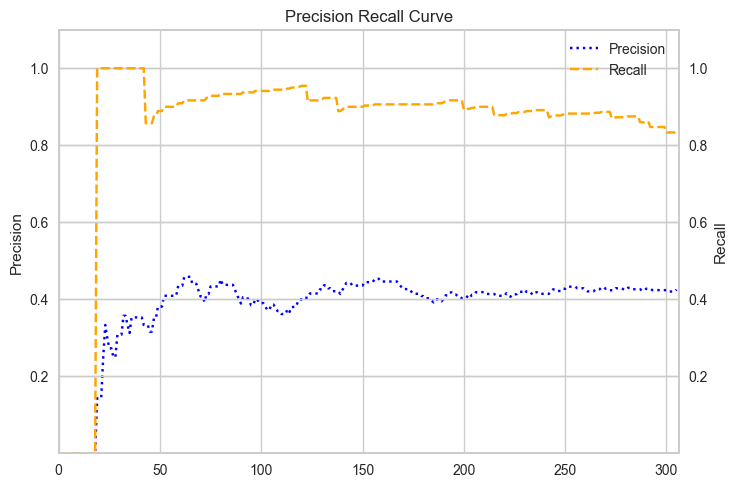

In [32]:
fig, ax1 = plt.subplots()
ax1.set_title("Precision Recall Curve")
ax1.set_ylabel("Precision")
ax1.set_xticks(range(0, len(pred_df), 50))
ax1.set_yticks([0.2, 0.4, 0.6, 0.8, 1])
ax1.set_xlim(left=0, right=len(pred_df))
ax1.set_ylim(bottom=0, top=1.1)
ln1 = ax1.plot(pred_df["precision"], label="Precision", linestyle=":", color="blue")
ax2 = ax1.twinx()
ax2.set_ylabel("Recall")
ax2.set_xticks(range(0, len(pred_df), 50))
ax2.set_yticks([0.2, 0.4, 0.6, 0.8, 1])
ax2.set_xlim(left=0, right=len(pred_df))
ax2.set_ylim(bottom=0, top=1.1)
ln2 = ax2.plot(pred_df["recall"], label="Recall", linestyle="--", color="orange")
lns = ln1 + ln2
labs = [l.get_label() for l in lns]
plt.legend(lns, labs, loc=0)
plt.show()